Full Analysis: Medal Performance vs Market Outcomes

This notebook **rebuilds a full trading-day panel** (medal days *and* non-medal days) and runs the complete set of analyses:

## Results in
1. **Summary stats** (medal variables + market variables)
2. **Correlation matrix** (medals ↔ returns/volume/volatility/abnormal returns)
3. **Difference-in-means**: medal days vs non-medal days
4. **Core regressions**:
   - Any medal dummy
   - Total medals
   - Performance score
   - Total medals + performance score together
5. **Abnormal returns** (rolling CAPM + FF3) for sentiment-exposed tickers
6. **Sector heterogeneity** (SPY vs NKE vs XLY vs DKNG)
7. **Volume & volatility regressions**
8. **Summer vs Winter** interaction tests
9. **Lead/Lag tests** (k = -1, 0, +1)
10. **Large shock vs small shock** (top vs bottom quartiles)
11. **Placebo tests** (randomized medal days)
12. **CAR event windows** ([-1, +1] and [-1, +3]) for abnormal returns
13. **Economic magnitude** (bps per point; illustrative $ impact)
14. **Exports** of key result tables for your final PDF

> Data inputs expected:
- `usa_medal_daily_counts_and_score_ALL.csv`

> Online data at runtime:
- Yahoo Finance for prices/volume
- Ken French daily factors via `pandas_datareader`


In [9]:
# Install dependencies if needed (comment out if already installed)
%pip -q install pandas numpy yfinance pandas_datareader pandas_market_calendars statsmodels tqdm scipy

Note: you may need to restart the kernel to use updated packages.


In [10]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import yfinance as yf
import pandas_market_calendars as mcal
from pandas_datareader import data as pdr
import statsmodels.api as sm
from statsmodels.regression.rolling import RollingOLS
from tqdm.auto import tqdm
from scipy import stats

import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 300)

## 1) Load medal-day data (ALL) and map to NYSE trading days

In [11]:
# ---- locate medal-day ALL file ----
CANDIDATES = [
    Path("../outputs/usa_medal_daily_counts_and_score_ALL.csv"),
]
medal_path = next((p for p in CANDIDATES if p.exists()), None)
if medal_path is None:
    raise FileNotFoundError("Could not find usa_medal_daily_counts_and_score_ALL.csv")

medals = pd.read_csv(medal_path)
if "event_date_end" in medals.columns:
    medals = medals.rename(columns={"event_date_end":"medal_date"})
elif "date" in medals.columns:
    medals = medals.rename(columns={"date":"medal_date"})
elif "medal_date" not in medals.columns:
    raise ValueError("Expected a date column: event_date_end / date / medal_date")

medals["medal_date"] = pd.to_datetime(medals["medal_date"], errors="coerce")
medals = medals.dropna(subset=["medal_date"]).sort_values("medal_date").reset_index(drop=True)

# Ensure required columns
for c in ["gold","silver","bronze","performance_score","total_medals","season"]:
    if c not in medals.columns:
        raise ValueError(f"Missing required column '{c}' in medal CSV")

# Any medal dummy
medals["any_medal_dummy"] = (medals["total_medals"] > 0).astype(int)

display(medals.head())
print("Medal days:", len(medals), "Range:", medals["medal_date"].min().date(), "→", medals["medal_date"].max().date())

,medal_date,total_medals,gold,silver,bronze,performance_score,season,any_medal_dummy
0,2000-01-01,23,10,6,7,49,S,1
1,2000-02-01,13,3,5,5,24,S,1
2,2000-02-16,2,0,0,2,2,S,1
3,2000-03-01,1,0,0,1,1,S,1
4,2000-04-01,2,2,0,0,6,S,1


Medal days: 281 Range: 2000-01-01 → 2022-11-25


In [12]:
# Map medal dates to next NYSE trading day
nyse = mcal.get_calendar("NYSE")

start = medals["medal_date"].min() - pd.Timedelta(days=10)
end = medals["medal_date"].max() + pd.Timedelta(days=10)
schedule = nyse.schedule(start_date=start, end_date=end)
trading_days = pd.DatetimeIndex(schedule.index)

def to_next_trading_day(d: pd.Timestamp) -> pd.Timestamp:
    if d in trading_days:
        return d
    idx = trading_days.searchsorted(d)
    return trading_days[idx] if idx < len(trading_days) else pd.NaT

medals["trade_date"] = medals["medal_date"].apply(to_next_trading_day)
medals = medals.dropna(subset=["trade_date"]).sort_values("trade_date").reset_index(drop=True)

display(medals.head(10)[["medal_date","trade_date","season","gold","silver","bronze","performance_score"]])

,medal_date,trade_date,season,gold,silver,bronze,performance_score
0,2000-01-01,2000-01-03,S,10,6,7,49
1,2000-02-01,2000-02-01,S,3,5,5,24
2,2000-02-16,2000-02-16,S,0,0,2,2
3,2000-03-01,2000-03-01,S,0,0,1,1
4,2000-04-01,2000-04-03,S,2,0,0,6
5,2000-04-23,2000-04-24,S,0,0,1,1
6,2000-05-10,2000-05-10,S,0,0,1,1
7,2000-06-01,2000-06-01,S,1,0,1,4
8,2000-07-01,2000-07-03,S,1,0,0,3
9,2000-07-09,2000-07-10,S,1,0,0,3


## 2) Build a full trading-day panel (includes non-medal days)

We create a NYSE trading-day index covering the entire medal range and merge medal variables onto it (non-medal days become zeros).


In [13]:
full_schedule = nyse.schedule(start_date=medals["trade_date"].min(), end_date=medals["trade_date"].max())
full_trading_days = pd.DatetimeIndex(full_schedule.index)

panel = pd.DataFrame({"trade_date": full_trading_days})

panel = panel.merge(
    medals[["trade_date","season","gold","silver","bronze","total_medals","performance_score","any_medal_dummy"]],
    on="trade_date",
    how="left",
)

for c in ["gold","silver","bronze","total_medals","performance_score","any_medal_dummy"]:
    panel[c] = panel[c].fillna(0)

panel["winter_dummy"] = (panel["season"] == "W").astype(int)
panel["summer_dummy"] = (panel["season"] == "S").astype(int)

print("Full trading-day panel shape:", panel.shape)
display(panel.head(10))

Full trading-day panel shape: (5788, 10)


,trade_date,season,gold,silver,bronze,total_medals,performance_score,any_medal_dummy,winter_dummy,summer_dummy
0,2000-01-03,S,10.0,6.0,7.0,23.0,49.0,1.0,0,1
1,2000-01-04,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0
2,2000-01-05,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0
3,2000-01-06,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0
4,2000-01-07,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0
5,2000-01-10,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0
6,2000-01-11,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0
7,2000-01-12,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0
8,2000-01-13,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0
9,2000-01-14,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0


## 3) Fetch market data (Yahoo Finance) + compute returns/volume/volatility

In [14]:
TICKERS = ["SPY","NKE","XLY","DKNG"]  # edit as desired

fetch_start = (panel["trade_date"].min() - pd.Timedelta(days=365)).date()
fetch_end = (panel["trade_date"].max() + pd.Timedelta(days=10)).date()

print("Fetching:", TICKERS, "from", fetch_start, "to", fetch_end)
raw = yf.download(TICKERS, start=str(fetch_start), end=str(fetch_end), auto_adjust=False, progress=False)

prices = raw["Adj Close"] if "Adj Close" in raw else raw["Close"]
volume = raw["Volume"]

if isinstance(prices, pd.Series): prices = prices.to_frame()
if isinstance(volume, pd.Series): volume = volume.to_frame()

ret = np.log(prices).diff()
lvc = np.log(volume.replace(0, np.nan)).diff()
absret = ret.abs()
vol20 = ret.rolling(20).std()

def wide_metric(df: pd.DataFrame, prefix: str) -> pd.DataFrame:
    out = df.copy()
    out.columns = [f"{prefix}_{c}" for c in out.columns]
    out.index.name = "trade_date"
    return out

mkt_wide = pd.concat([
    wide_metric(ret, "ret"),
    wide_metric(lvc, "lvc"),
    wide_metric(absret, "absret"),
    wide_metric(vol20, "vol20"),
], axis=1).reset_index()

panel = panel.merge(mkt_wide, on="trade_date", how="left")

print("Panel with market metrics:", panel.shape)
display(panel.head())

Fetching: ['SPY', 'NKE', 'XLY', 'DKNG'] from 1999-01-03 to 2022-12-05
Panel with market metrics: (5788, 26)


,trade_date,season,gold,silver,bronze,total_medals,performance_score,any_medal_dummy,winter_dummy,summer_dummy,ret_DKNG,ret_NKE,ret_SPY,ret_XLY,lvc_DKNG,lvc_NKE,lvc_SPY,lvc_XLY,absret_DKNG,absret_NKE,absret_SPY,absret_XLY,vol20_DKNG,vol20_NKE,vol20_SPY,vol20_XLY
0,2000-01-03,S,10.0,6.0,7.0,23.0,49.0,1.0,0,1,NaN,-0.029433,-0.009836,-0.030646,NaN,1.492121,0.945188,2.411134,NaN,0.029433,0.009836,0.030646,NaN,0.047884,0.007373,0.016392
1,2000-01-04,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0,NaN,-0.056089,-0.039891,-0.030545,NaN,0.202203,-0.009167,-0.183544,NaN,0.056089,0.039891,0.030545,NaN,0.049479,0.011608,0.017940
2,2000-01-05,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0,NaN,0.056089,0.001787,-0.012375,NaN,-0.405139,0.409019,-0.352170,NaN,0.056089,0.001787,0.012375,NaN,0.051024,0.011496,0.017741
3,2000-01-06,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0,NaN,-0.005208,-0.016202,0.011305,NaN,-0.290866,-0.670696,0.086075,NaN,0.005208,0.016202,0.011305,NaN,0.050609,0.011962,0.017831
4,2000-01-07,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0,NaN,0.000000,0.056452,0.046033,NaN,-0.202745,0.258793,-0.662688,NaN,0.000000,0.056452,0.046033,NaN,0.050567,0.017541,0.020392


## 4) Load Fama–French daily factors + compute abnormal returns (rolling CAPM + FF3)

In [15]:
ff = pdr.DataReader("F-F_Research_Data_Factors_daily", "famafrench")[0].copy()
ff.index = pd.to_datetime(ff.index)
ff = ff.rename(columns={"Mkt-RF":"MKT_RF"})[["MKT_RF","SMB","HML","RF"]].sort_index() / 100.0

display(ff.head())
print("Factor coverage:", ff.index.min().date(), "→", ff.index.max().date())

,MKT_RF,SMB,HML,RF
Date,,,,
2021-03-10,0.0067,0.0077,0.0182,0.0
2021-03-11,0.0141,0.0159,-0.0200,0.0
2021-03-12,0.0011,0.0014,0.0129,0.0
2021-03-15,0.0069,-0.0012,-0.0127,0.0
2021-03-16,-0.0041,-0.0109,-0.0085,0.0


Factor coverage: 2021-03-10 → 2026-01-30


In [16]:
ROLLING_WINDOW = 120

def rolling_abrets(ticker: str) -> pd.DataFrame:
    r = ret[ticker].dropna()
    dfm = pd.DataFrame({"ret": r}).join(ff, how="inner").dropna()
    dfm["excess_ret"] = dfm["ret"] - dfm["RF"]
    y = dfm["excess_ret"]

    Xc = sm.add_constant(dfm[["MKT_RF"]])
    capm = RollingOLS(y, Xc, window=ROLLING_WINDOW, min_nobs=max(60, int(ROLLING_WINDOW*0.5))).fit()
    capm_pred = (Xc * capm.params).sum(axis=1)
    dfm["abret_capm"] = y - capm_pred

    Xf = sm.add_constant(dfm[["MKT_RF","SMB","HML"]])
    ff3 = RollingOLS(y, Xf, window=ROLLING_WINDOW, min_nobs=max(60, int(ROLLING_WINDOW*0.5))).fit()
    ff3_pred = (Xf * ff3.params).sum(axis=1)
    dfm["abret_ff3"] = y - ff3_pred

    out = dfm[["abret_capm","abret_ff3"]].copy()
    out.index.name = "trade_date"
    out = out.reset_index()
    out.columns = ["trade_date", f"abret_capm_{ticker}", f"abret_ff3_{ticker}"]
    return out

ab_wide = None
for t in [x for x in TICKERS if x != "SPY"]:
    tmp = rolling_abrets(t)
    ab_wide = tmp if ab_wide is None else ab_wide.merge(tmp, on="trade_date", how="outer")

panel = panel.merge(ab_wide, on="trade_date", how="left")
print("Panel with abnormal returns:", panel.shape)
display(panel.head())

Panel with abnormal returns: (5788, 32)


,trade_date,season,gold,silver,bronze,total_medals,performance_score,any_medal_dummy,winter_dummy,summer_dummy,ret_DKNG,ret_NKE,ret_SPY,ret_XLY,lvc_DKNG,lvc_NKE,lvc_SPY,lvc_XLY,absret_DKNG,absret_NKE,absret_SPY,absret_XLY,vol20_DKNG,vol20_NKE,vol20_SPY,vol20_XLY,abret_capm_NKE,abret_ff3_NKE,abret_capm_XLY,abret_ff3_XLY,abret_capm_DKNG,abret_ff3_DKNG
0,2000-01-03,S,10.0,6.0,7.0,23.0,49.0,1.0,0,1,NaN,-0.029433,-0.009836,-0.030646,NaN,1.492121,0.945188,2.411134,NaN,0.029433,0.009836,0.030646,NaN,0.047884,0.007373,0.016392,NaN,NaN,NaN,NaN,NaN,NaN
1,2000-01-04,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0,NaN,-0.056089,-0.039891,-0.030545,NaN,0.202203,-0.009167,-0.183544,NaN,0.056089,0.039891,0.030545,NaN,0.049479,0.011608,0.017940,NaN,NaN,NaN,NaN,NaN,NaN
2,2000-01-05,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0,NaN,0.056089,0.001787,-0.012375,NaN,-0.405139,0.409019,-0.352170,NaN,0.056089,0.001787,0.012375,NaN,0.051024,0.011496,0.017741,NaN,NaN,NaN,NaN,NaN,NaN
3,2000-01-06,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0,NaN,-0.005208,-0.016202,0.011305,NaN,-0.290866,-0.670696,0.086075,NaN,0.005208,0.016202,0.011305,NaN,0.050609,0.011962,0.017831,NaN,NaN,NaN,NaN,NaN,NaN
4,2000-01-07,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0,0,NaN,0.000000,0.056452,0.046033,NaN,-0.202745,0.258793,-0.662688,NaN,0.000000,0.056452,0.046033,NaN,0.050567,0.017541,0.020392,NaN,NaN,NaN,NaN,NaN,NaN


## 5) Regression helpers

In [17]:
def add_calendar_controls(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["dow"] = out["trade_date"].dt.dayofweek
    out["month"] = out["trade_date"].dt.month
    out = pd.get_dummies(out, columns=["dow","month"], drop_first=True)
    return out

def run_ols(df: pd.DataFrame, y: str, X: list[str], robust: str="HC3"):
    # Subset
    d = df[[y] + X].copy()

    # Force numeric (turns bad strings into NaN)
    d[y] = pd.to_numeric(d[y], errors="coerce")
    for c in X:
        d[c] = pd.to_numeric(d[c], errors="coerce")

    # Drop missing
    d = d.dropna()

    # Build and fit
    Xmat = sm.add_constant(d[X].astype(float))
    yvec = d[y].astype(float)

    return sm.OLS(yvec, Xmat).fit(cov_type=robust)

def coef_table(models: dict):
    rows = []
    for name, m in models.items():
        for p in m.params.index:
            rows.append({
                "model": name,
                "param": p,
                "coef": m.params[p],
                "t": m.tvalues[p],
                "p": m.pvalues[p],
                "n": int(m.nobs),
                "r2": m.rsquared,
            })
    return pd.DataFrame(rows)

## 6) Summary stats + correlation heatmap

,count,mean,std,min,25%,50%,75%,max
gold,5788.0,0.043711,0.372722,0.000000,0.000000,0.000000,0.000000,10.000000
silver,5788.0,0.041983,0.344499,0.000000,0.000000,0.000000,0.000000,11.000000
bronze,5788.0,0.039392,0.313020,0.000000,0.000000,0.000000,0.000000,11.000000
total_medals,5788.0,0.125086,0.894025,0.000000,0.000000,0.000000,0.000000,26.000000
performance_score,5788.0,0.254492,1.885807,0.000000,0.000000,0.000000,0.000000,54.000000
any_medal_dummy,5788.0,0.048549,0.214941,0.000000,0.000000,0.000000,0.000000,1.000000
winter_dummy,5788.0,0.013822,0.116761,0.000000,0.000000,0.000000,0.000000,1.000000
ret_SPY,5788.0,0.000253,0.012497,-0.115887,-0.004801,0.000658,0.005985,0.135577
lvc_SPY,5788.0,-0.000606,0.332036,-1.759934,-0.211324,-0.005653,0.204956,1.730330
absret_SPY,5788.0,0.008245,0.009394,0.000000,0.002254,0.005480,0.010825,0.135577


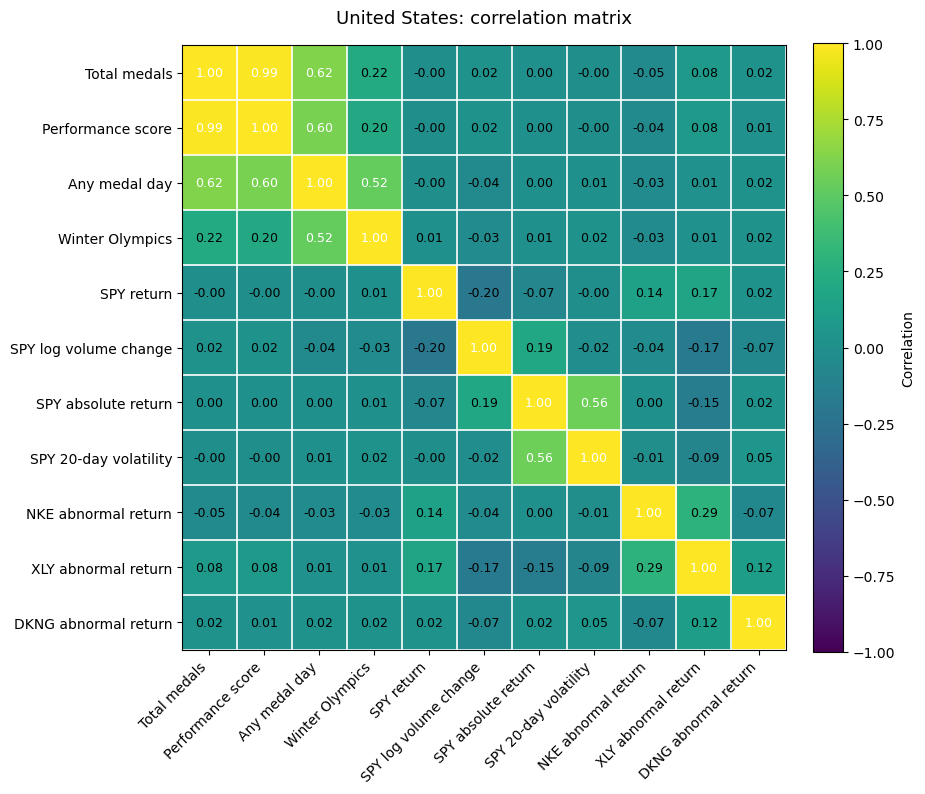

,Total medals,Performance score,Any medal day,Winter Olympics,SPY return,SPY log volume change,SPY absolute return,SPY 20-day volatility,NKE abnormal return,XLY abnormal return,DKNG abnormal return
Total medals,1.000000,0.986276,0.619444,0.220156,-0.002846,0.016490,0.002857,-0.002079,-0.046881,0.079524,0.016465
Performance score,0.986276,1.000000,0.597474,0.203763,-0.002075,0.017374,0.002771,-0.003242,-0.042535,0.083898,0.008908
Any medal day,0.619444,0.597474,1.000000,0.524092,-0.002917,-0.041747,0.002602,0.005779,-0.034103,0.009372,0.017854
Winter Olympics,0.220156,0.203763,0.524092,1.000000,0.005610,-0.033217,0.006405,0.020779,-0.034103,0.009372,0.017854
SPY return,-0.002846,-0.002075,-0.002917,0.005610,1.000000,-0.199155,-0.073674,-0.004537,0.144896,0.167982,0.017432
SPY log volume change,0.016490,0.017374,-0.041747,-0.033217,-0.199155,1.000000,0.189434,-0.017563,-0.037431,-0.165661,-0.068925
SPY absolute return,0.002857,0.002771,0.002602,0.006405,-0.073674,0.189434,1.000000,0.561015,0.002288,-0.150616,0.019045
SPY 20-day volatility,-0.002079,-0.003242,0.005779,0.020779,-0.004537,-0.017563,0.561015,1.000000,-0.014802,-0.090819,0.047012
NKE abnormal return,-0.046881,-0.042535,-0.034103,-0.034103,0.144896,-0.037431,0.002288,-0.014802,1.000000,0.291845,-0.068716
XLY abnormal return,0.079524,0.083898,0.009372,0.009372,0.167982,-0.165661,-0.150616,-0.090819,0.291845,1.000000,0.119704


In [18]:
dfc = add_calendar_controls(panel)
control_cols = [c for c in dfc.columns if c.startswith("dow_") or c.startswith("month_")]

# Summary stats for medal vars + key SPY vars + one exposed ticker (if present)
summary_cols = ["gold","silver","bronze","total_medals","performance_score","any_medal_dummy","winter_dummy"]
for c in ["ret_SPY","lvc_SPY","absret_SPY","vol20_SPY"]:
    if c in dfc.columns:
        summary_cols.append(c)
for t in [x for x in TICKERS if x != "SPY"]:
    c = f"abret_ff3_{t}"
    if c in dfc.columns:
        summary_cols.append(c)
        break

display(dfc[summary_cols].describe().T)

# Correlation matrix (selected)
corr_cols = ["total_medals","performance_score","any_medal_dummy","winter_dummy"]
for c in ["ret_SPY","lvc_SPY","absret_SPY","vol20_SPY"]:
    if c in dfc.columns:
        corr_cols.append(c)
for t in [x for x in TICKERS if x != "SPY"]:
    c = f"abret_ff3_{t}"
    if c in dfc.columns:
        corr_cols.append(c)

corr = dfc[corr_cols].corr()

# Pretty labels for presentation
pretty_labels = {
    "total_medals": "Total medals",
    "performance_score": "Performance score",
    "any_medal_dummy": "Any medal day",
    "winter_dummy": "Winter Olympics",
    "ret_SPY": "SPY return",
    "lvc_SPY": "SPY log volume change",
    "absret_SPY": "SPY absolute return",
    "vol20_SPY": "SPY 20-day volatility",
}
for t in [x for x in TICKERS if x != "SPY"]:
    pretty_labels[f"abret_ff3_{t}"] = f"{t} abnormal return"

corr_pretty = corr.copy()
corr_pretty.index = [pretty_labels.get(c, c) for c in corr_pretty.index]
corr_pretty.columns = [pretty_labels.get(c, c) for c in corr_pretty.columns]

# Save folder
fig_dir = Path("us_presentation_figures")
fig_dir.mkdir(exist_ok=True)

# Plot
n = len(corr_pretty)
fig_size = max(7, 0.85 * n)

fig, ax = plt.subplots(figsize=(fig_size, fig_size))
im = ax.imshow(corr_pretty.values, vmin=-1, vmax=1, aspect="equal")

ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(corr_pretty.columns, rotation=45, ha="right", fontsize=10)
ax.set_yticklabels(corr_pretty.index, fontsize=10)

# Annotate each cell
for i in range(n):
    for j in range(n):
        val = corr_pretty.iloc[i, j]
        txt_color = "white" if abs(val) >= 0.5 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9, color=txt_color)

# Minor gridlines for clean matrix appearance
ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=1.2)
ax.tick_params(which="minor", bottom=False, left=False)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Correlation", rotation=90)

ax.set_title("United States: correlation matrix", pad=16, fontsize=13)

fig.tight_layout()
fig.savefig(fig_dir / "correlation_matrix.png", bbox_inches="tight", dpi=300)
plt.show()

display(corr_pretty)

## 7) Difference in means (medal vs non-medal days)

In [19]:
def diff_means(df: pd.DataFrame, col: str):
    a = df.loc[df["any_medal_dummy"]==1, col].dropna()
    b = df.loc[df["any_medal_dummy"]==0, col].dropna()
    tstat, pval = stats.ttest_ind(a, b, equal_var=False)
    return {
        "metric": col,
        "mean_medal": a.mean(),
        "mean_nonmedal": b.mean(),
        "diff": a.mean() - b.mean(),
        "t": tstat,
        "p": pval,
        "n_medal": len(a),
        "n_nonmedal": len(b),
    }

metrics = [c for c in ["ret_SPY","lvc_SPY","absret_SPY","vol20_SPY"] if c in dfc.columns]
diff_tbl = pd.DataFrame([diff_means(dfc, c) for c in metrics])
display(diff_tbl)

,metric,mean_medal,mean_nonmedal,diff,t,p,n_medal,n_nonmedal
0,ret_SPY,0.000092,0.000261,-0.000170,-0.221070,0.825184,281,5507
1,lvc_SPY,-0.061965,0.002525,-0.064490,-3.120896,0.001974,281,5507
2,absret_SPY,0.008353,0.008239,0.000114,0.198828,0.842528,281,5507
3,vol20_SPY,0.010673,0.010487,0.000186,0.505225,0.613748,281,5507


## 8) Core regressions (SPY outcomes)

In [20]:
Y_LIST = [c for c in ["ret_SPY","lvc_SPY","absret_SPY","vol20_SPY"] if c in dfc.columns]

models = {}
bad = dfc[["ret_SPY","lvc_SPY","absret_SPY","vol20_SPY","any_medal_dummy","total_medals","performance_score"] + control_cols].dtypes
display(bad[bad == "object"])

for y in Y_LIST:
    models[f"{y} ~ any + ctrls"] = run_ols(dfc, y, ["any_medal_dummy"] + control_cols)
    models[f"{y} ~ total + ctrls"] = run_ols(dfc, y, ["total_medals"] + control_cols)
    models[f"{y} ~ score + ctrls"] = run_ols(dfc, y, ["performance_score"] + control_cols)
    models[f"{y} ~ total+score + ctrls"] = run_ols(dfc, y, ["total_medals","performance_score"] + control_cols)

tbl_core = coef_table(models)
display(tbl_core.sort_values(["model","param"]))

Series([], dtype: object)

,model,param,coef,t,p,n,r2
139,absret_SPY ~ any + ctrls,any_medal_dummy,0.000320,0.534984,5.926611e-01,5788,0.009345
138,absret_SPY ~ any + ctrls,const,0.008269,17.249580,1.127167e-66,5788,0.009345
140,absret_SPY ~ any + ctrls,dow_1,-0.000020,-0.046643,9.627977e-01,5788,0.009345
141,absret_SPY ~ any + ctrls,dow_2,-0.000245,-0.578466,5.629497e-01,5788,0.009345
142,absret_SPY ~ any + ctrls,dow_3,-0.000118,-0.272546,7.852024e-01,5788,0.009345
...,...,...,...,...,...,...,...
270,vol20_SPY ~ total+score + ctrls,month_7,0.000137,0.453544,6.501569e-01,5788,0.015471
271,vol20_SPY ~ total+score + ctrls,month_8,0.000102,0.289167,7.724537e-01,5788,0.015471
272,vol20_SPY ~ total+score + ctrls,month_9,0.000398,1.138507,2.549089e-01,5788,0.015471
260,vol20_SPY ~ total+score + ctrls,performance_score,-0.000158,-0.682588,4.948670e-01,5788,0.015471


## 9) Sector heterogeneity (returns + abnormal returns)

In [21]:
models_sec = {}
exposed = [t for t in TICKERS if t != "SPY"]

for t in exposed:
    y_raw = f"ret_{t}"
    y_ab = f"abret_ff3_{t}"
    if y_raw in dfc.columns:
        models_sec[f"{y_raw} ~ score + ctrls"] = run_ols(dfc, y_raw, ["performance_score"] + control_cols)
        models_sec[f"{y_raw} ~ total+score + ctrls"] = run_ols(dfc, y_raw, ["total_medals","performance_score"] + control_cols)
    if y_ab in dfc.columns:
        models_sec[f"{y_ab} ~ score + ctrls"] = run_ols(dfc, y_ab, ["performance_score"] + control_cols)
        models_sec[f"{y_ab} ~ total+score + ctrls"] = run_ols(dfc, y_ab, ["total_medals","performance_score"] + control_cols)

tbl_sec = coef_table(models_sec)
display(tbl_sec.sort_values(["model","param"]).head(120))

,model,param,coef,t,p,n,r2
175,abret_ff3_DKNG ~ score + ctrls,const,0.001737,0.185543,0.852803,436,0.033251
177,abret_ff3_DKNG ~ score + ctrls,dow_1,0.011933,2.110397,0.034824,436,0.033251
178,abret_ff3_DKNG ~ score + ctrls,dow_2,0.008998,1.512957,0.130290,436,0.033251
179,abret_ff3_DKNG ~ score + ctrls,dow_3,-0.003251,-0.585042,0.558519,436,0.033251
180,abret_ff3_DKNG ~ score + ctrls,dow_4,0.001765,0.236831,0.812788,436,0.033251
...,...,...,...,...,...,...,...
148,ret_DKNG ~ score + ctrls,month_4,-0.004111,-0.541863,0.587913,849,0.027082
149,ret_DKNG ~ score + ctrls,month_5,0.005019,0.537695,0.590787,849,0.027082
150,ret_DKNG ~ score + ctrls,month_6,-0.009057,-1.072805,0.283358,849,0.027082
151,ret_DKNG ~ score + ctrls,month_7,-0.003864,-0.520474,0.602733,849,0.027082


## 10) Summer vs Winter interaction

In [22]:
dfc["score_x_winter"] = dfc["performance_score"] * dfc["winter_dummy"]

models_int = {}
targets = ["ret_SPY"] + [f"abret_ff3_{t}" for t in exposed]
targets = [t for t in targets if t in dfc.columns]

for y in targets:
    X = ["performance_score","winter_dummy","score_x_winter"] + control_cols
    models_int[f"{y} ~ score + winter + interaction + ctrls"] = run_ols(dfc, y, X)

tbl_int = coef_table(models_int)
display(tbl_int.sort_values(["model","param"]))

,model,param,coef,t,p,n,r2
57,abret_ff3_DKNG ~ score + winter + interaction ...,const,0.001710,0.182831,0.854931,436,0.033256
61,abret_ff3_DKNG ~ score + winter + interaction ...,dow_1,0.011940,2.114852,0.034443,436,0.033256
62,abret_ff3_DKNG ~ score + winter + interaction ...,dow_2,0.008992,1.507489,0.131685,436,0.033256
63,abret_ff3_DKNG ~ score + winter + interaction ...,dow_3,-0.003264,-0.582925,0.559944,436,0.033256
64,abret_ff3_DKNG ~ score + winter + interaction ...,dow_4,0.001758,0.236427,0.813101,436,0.033256
...,...,...,...,...,...,...,...
14,ret_SPY ~ score + winter + interaction + ctrls,month_8,0.000401,0.548827,0.583124,5788,0.002634
15,ret_SPY ~ score + winter + interaction + ctrls,month_9,-0.000503,-0.639052,0.522789,5788,0.002634
1,ret_SPY ~ score + winter + interaction + ctrls,performance_score,-0.000038,-0.405294,0.685261,5788,0.002634
3,ret_SPY ~ score + winter + interaction + ctrls,score_x_winter,0.000865,2.833906,0.004598,5788,0.002634


## 11) Lead / lag tests (k = -1, 0, +1)

In [23]:
df_ll = dfc.copy()
df_ll["score_lag1"] = df_ll["performance_score"].shift(1)
df_ll["score_lead1"] = df_ll["performance_score"].shift(-1)

models_ll = {}
for y in targets:
    X = ["score_lag1","performance_score","score_lead1"] + control_cols
    models_ll[f"{y} ~ lag1 + t + lead1 + ctrls"] = run_ols(df_ll, y, X)

tbl_ll = coef_table(models_ll)
display(tbl_ll[tbl_ll["param"].isin(["score_lag1","performance_score","score_lead1"])].sort_values(["model","param"]))

,model,param,coef,t,p,n,r2
59,abret_ff3_DKNG ~ lag1 + t + lead1 + ctrls,performance_score,-0.000074,-0.028460,0.977296,435,0.044014
58,abret_ff3_DKNG ~ lag1 + t + lead1 + ctrls,score_lag1,0.001802,0.316008,0.751997,435,0.044014
60,abret_ff3_DKNG ~ lag1 + t + lead1 + ctrls,score_lead1,-0.005556,-0.835135,0.403642,435,0.044014
21,abret_ff3_NKE ~ lag1 + t + lead1 + ctrls,performance_score,-0.000423,-0.324755,0.745367,435,0.036816
20,abret_ff3_NKE ~ lag1 + t + lead1 + ctrls,score_lag1,0.001581,2.023534,0.043018,435,0.036816
22,abret_ff3_NKE ~ lag1 + t + lead1 + ctrls,score_lead1,0.000508,0.458555,0.646554,435,0.036816
40,abret_ff3_XLY ~ lag1 + t + lead1 + ctrls,performance_score,0.001245,1.350776,0.176767,435,0.043228
39,abret_ff3_XLY ~ lag1 + t + lead1 + ctrls,score_lag1,0.000157,0.478458,0.632324,435,0.043228
41,abret_ff3_XLY ~ lag1 + t + lead1 + ctrls,score_lead1,0.000335,0.805270,0.420664,435,0.043228
2,ret_SPY ~ lag1 + t + lead1 + ctrls,performance_score,0.000031,0.303599,0.761434,5786,0.002385


## 12) Large shock vs small shock (quartiles) + plot

,ret_SPY,abret_ff3_NKE,abret_ff3_XLY,abret_ff3_DKNG
shock_group,,,,
High (Q4),0.000822,-0.000222,0.009383,-0.010256
Low (Q1),-0.000036,-0.001641,-0.000840,0.001341
Mid,-0.000328,-0.005617,-0.002709,0.013335


<Figure size 640x480 with 0 Axes>

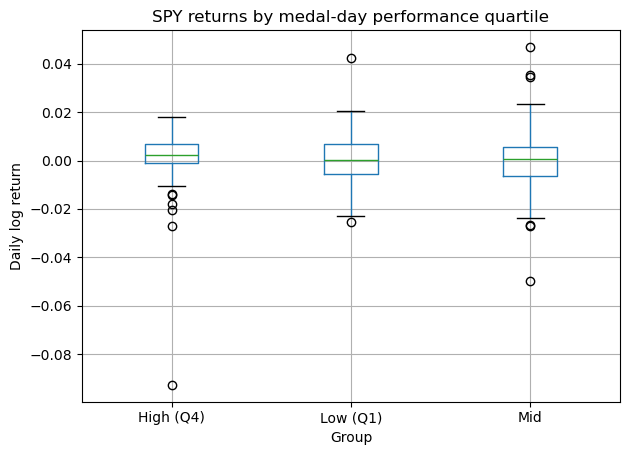

In [24]:
medal_days = dfc[dfc["any_medal_dummy"]==1].copy()
q1 = medal_days["performance_score"].quantile(0.25)
q3 = medal_days["performance_score"].quantile(0.75)

medal_days["shock_group"] = np.where(medal_days["performance_score"]>=q3, "High (Q4)",
                             np.where(medal_days["performance_score"]<=q1, "Low (Q1)", "Mid"))

cols_show = [c for c in targets if c in medal_days.columns]
display(medal_days.groupby("shock_group")[cols_show].mean())

if "ret_SPY" in medal_days.columns:
    plt.figure()
    medal_days.boxplot(column="ret_SPY", by="shock_group")
    plt.title("SPY returns by medal-day performance quartile")
    plt.suptitle("")
    plt.xlabel("Group")
    plt.ylabel("Daily log return")
    plt.tight_layout()
    plt.show()

run_ols(dfc[dfc["any_medal_dummy"]==1], 
        "abret_ff3_XLY", 
        ["performance_score"] + control_cols)

## 13) Placebo tests (random medal days)

100%|██████████| 200/200 [00:04<00:00, 43.35it/s]


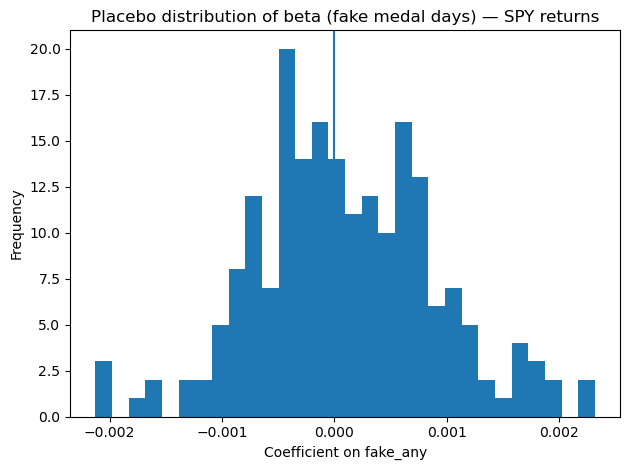

Real beta (any_medal_dummy): -3.894857715676714e-06


In [25]:
np.random.seed(42)

N_PLACEBO = 200
real_dates = set(dfc.loc[dfc["any_medal_dummy"]==1, "trade_date"])
n_events = len(real_dates)
all_dates = dfc["trade_date"].values

y_target = "ret_SPY"
placebo_betas = []

for _ in tqdm(range(N_PLACEBO)):
    fake_dates = set(np.random.choice(all_dates, size=n_events, replace=False))
    dfp = dfc.copy()
    dfp["fake_any"] = dfp["trade_date"].isin(fake_dates).astype(int)
    m = run_ols(dfp, y_target, ["fake_any"] + control_cols)
    placebo_betas.append(m.params.get("fake_any", np.nan))

m_real = run_ols(dfc, y_target, ["any_medal_dummy"] + control_cols)
real_beta = m_real.params.get("any_medal_dummy", np.nan)

plt.figure()
plt.hist([b for b in placebo_betas if np.isfinite(b)], bins=30)
plt.axvline(real_beta)
plt.title("Placebo distribution of beta (fake medal days) — SPY returns")
plt.xlabel("Coefficient on fake_any")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Real beta (any_medal_dummy):", real_beta)

## 14) CAR windows (abnormal returns)

In [26]:
def compute_car(df: pd.DataFrame, ar_col: str, window=(-1,1)) -> pd.Series:
    lo, hi = window
    df2 = df.reset_index(drop=True).copy()
    medal_idx = df2.index[df2["any_medal_dummy"]==1]
    cars = []
    for i in medal_idx:
        s = i + lo
        e = i + hi
        if s < 0 or e >= len(df2):
            continue
        w = df2.loc[s:e, ar_col]
        if w.isna().any():
            continue
        cars.append(w.sum())
    return pd.Series(cars)

car_rows = []
for t in exposed:
    ar = f"abret_ff3_{t}"
    if ar not in dfc.columns:
        continue
    car_111 = compute_car(dfc, ar, (-1,1))
    car_113 = compute_car(dfc, ar, (-1,3))
    car_rows.append({
        "ticker": t,
        "CAR_-1_+1_mean": car_111.mean(),
        "CAR_-1_+1_n": len(car_111),
        "CAR_-1_+3_mean": car_113.mean(),
        "CAR_-1_+3_n": len(car_113),
    })

car_df = pd.DataFrame(car_rows)
display(car_df)

,ticker,CAR_-1_+1_mean,CAR_-1_+1_n,CAR_-1_+3_mean,CAR_-1_+3_n
0,NKE,0.002965,15,0.002237,15
1,XLY,0.001804,15,-0.000031,15
2,DKNG,-0.005757,15,-0.021605,15


## 15) Economic magnitude (bps per +10 performance points)

In [27]:
m = run_ols(dfc, "ret_SPY", ["performance_score"] + control_cols)
beta = m.params["performance_score"]
bps_per_10 = beta * 10 * 10000
print("beta:", beta)
print("Approx bps per +10 performance points:", bps_per_10)

beta: 2.6634529833572025e-06
Approx bps per +10 performance points: 0.26634529833572024


## 16) Export key results tables (CSV) for your final PDF

In [28]:
corr.to_csv("results_corr_matrix.csv")
diff_tbl.to_csv("results_diff_in_means.csv", index=False)
tbl_core.to_csv("results_core_regressions_long.csv", index=False)
tbl_sec.to_csv("results_sector_regressions_long.csv", index=False)
tbl_int.to_csv("results_season_interaction_long.csv", index=False)
tbl_ll.to_csv("results_lead_lag_long.csv", index=False)
car_df.to_csv("results_car_summary.csv", index=False)

print("Wrote: results_*.csv")

Wrote: results_*.csv
